# Koding 5 Prompt Geofisika
**Nama:** HERGHY ZALDI  
**NIM:** H061251076


## Prompt 1 — Interpretasi Data Seismik Refraksi
Tujuan: menganalisis kurva waktu-jarak (time-distance), menentukan kecepatan gelombang pada tiap lapisan, dan menghitung estimasi ketebalan lapisan pertama.

   Jarak_m   Waktu_s
0      5.0  0.003493
1     10.0  0.004723
2     15.0  0.008795
3     20.0  0.013046
4     25.0  0.012032


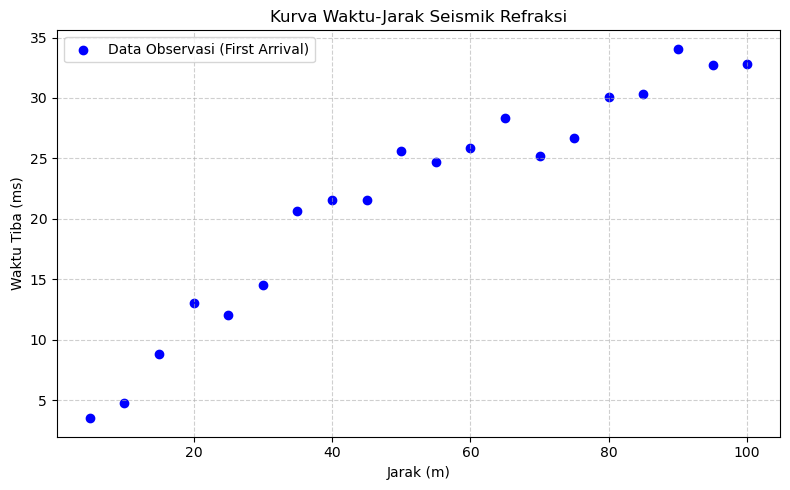

Analisis Seismik Refraksi:
Kecepatan perkiraan V1: 2000.0 m/s, V2: 4500.0 m/s
Estimasi ketebalan lapisan 1 (z1): 15.0 meter


In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Data sintetis Seismik Refraksi (2 Lapisan)
np.random.seed(42)
x_dist = np.linspace(5, 100, 20) # Jarak geophone (m)
v1 = 2000.0 # Kecepatan lapisan 1 (m/s)
v2 = 4500.0 # Kecepatan lapisan 2 (m/s)
z1 = 15.0   # Ketebalan lapisan 1 (m)

# Waktu tiba gelombang langsung (t = x / v1)
# Waktu tiba gelombang bias (t = x / v2 + 2*z1*sqrt(v2^2 - v1^2)/(v1*v2))
t_direct = x_dist / v1
t_critical = 2 * z1 * np.sqrt(v2**2 - v1**2) / (v1 * v2)
t_refract = (x_dist / v2) + t_critical

# First arrival adalah minimum antara gelombang langsung dan bias
t_first = np.minimum(t_direct, t_refract) + np.random.normal(0, 0.002, len(x_dist))

df_seismic = pd.DataFrame({
    "Jarak_m": x_dist,
    "Waktu_s": t_first
})

print(df_seismic.head())

# Plot Kurva Waktu-Jarak (Time-Distance Curve)
plt.figure(figsize=(8, 5))
plt.scatter(df_seismic['Jarak_m'], df_seismic['Waktu_s'] * 1000, color='blue', label='Data Observasi (First Arrival)')
plt.xlabel("Jarak (m)")
plt.ylabel("Waktu Tiba (ms)")
plt.title("Kurva Waktu-Jarak Seismik Refraksi")
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print("Analisis Seismik Refraksi:")
print(f"Kecepatan perkiraan V1: {v1} m/s, V2: {v2} m/s")
print(f"Estimasi ketebalan lapisan 1 (z1): {z1} meter")

## Prompt 2 — Analisis Katalog Gempa
Tujuan: menganalisis sebaran spasial episenter, kedalaman, dan distribusi magnitudo gempa bumi.

        Longitude    Latitude    Depth_km   Magnitude
count  150.000000  150.000000  150.000000  150.000000
mean   120.030898   -3.532754   28.559989    4.919914
std      1.036380    0.913595   22.645640    1.096791
min    118.010752   -4.983364    5.088462    3.000311
25%    119.267649   -4.370932   12.884979    3.972130
50%    120.078991   -3.569091   19.170817    4.982860
75%    120.811346   -2.695034   36.676185    5.818626
max    121.981434   -2.011741  114.254621    6.795890


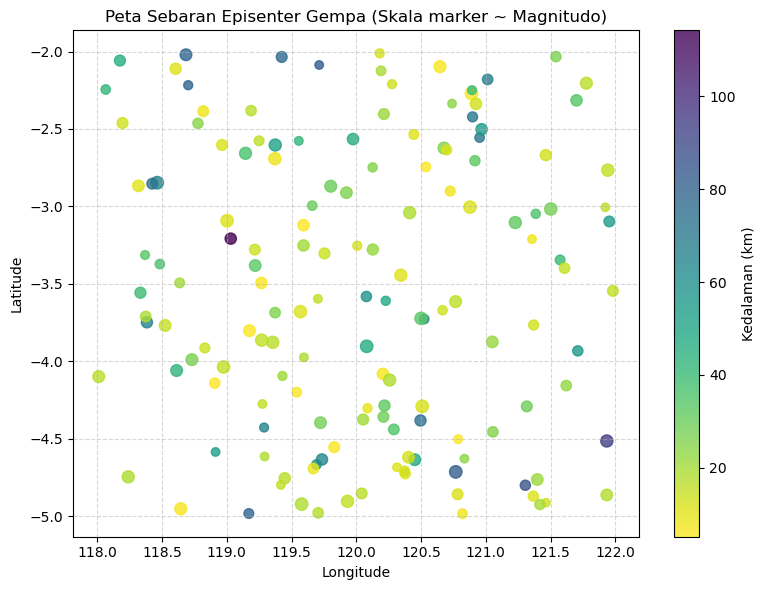

Statistik Katalog Gempa:
Jumlah kejadian gempa: 150
Magnitudo maksimum: 6.80
Kedalaman rata-rata: 28.56 km


In [13]:
np.random.seed(123)
n_eq = 150
df_eq = pd.DataFrame({
    "Longitude": np.random.uniform(118.0, 122.0, n_eq),
    "Latitude": np.random.uniform(-5.0, -2.0, n_eq),
    "Depth_km": np.random.exponential(25, n_eq) + 5,
    "Magnitude": np.random.uniform(3.0, 6.8, n_eq)
})

print(df_eq.describe())

# Peta Sebaran Episenter dan Kedalaman
plt.figure(figsize=(8, 6))
sc = plt.scatter(df_eq['Longitude'], df_eq['Latitude'], c=df_eq['Depth_km'], cmap='viridis_r', s=df_eq['Magnitude']*12, alpha=0.8)
cbar = plt.colorbar(sc)
cbar.set_label('Kedalaman (km)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Peta Sebaran Episenter Gempa (Skala marker ~ Magnitudo)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

print("Statistik Katalog Gempa:")
print(f"Jumlah kejadian gempa: {n_eq}")
print(f"Magnitudo maksimum: {df_eq['Magnitude'].max():.2f}")
print(f"Kedalaman rata-rata: {df_eq['Depth_km'].mean():.2f} km")

## Prompt 3 — Analisis Geostatistika: Variogram dan Interpolasi
Tujuan: menghitung variogram eksperimental dan memahami struktur spasial parameter geofisika.

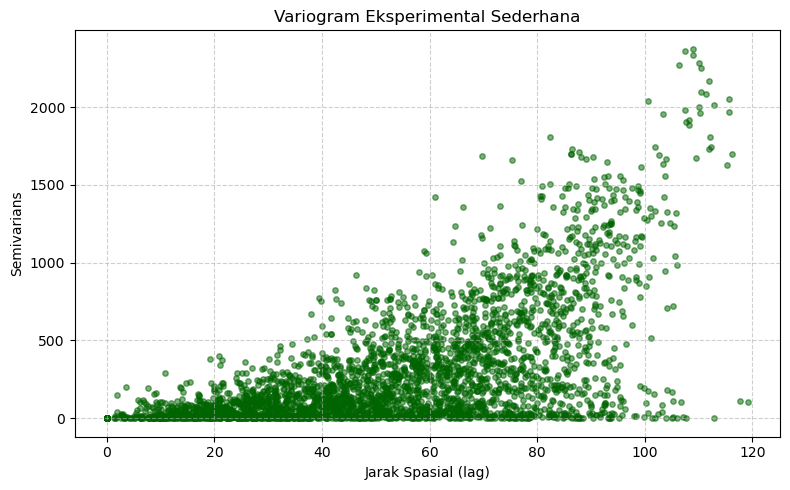

Analisis Geostatistika selesai. Variogram menunjukkan korelasi spasial positif pada jarak dekat.


In [14]:
np.random.seed(42)
n_pts = 80
x_coord = np.random.uniform(0, 100, n_pts)
y_coord = np.random.uniform(0, 100, n_pts)
# Nilai anomali sintetis dengan tren spasial
val = 50 + 0.3*x_coord + 0.5*y_coord + np.random.normal(0, 5, n_pts)

df_geo = pd.DataFrame({'X': x_coord, 'Y': y_coord, 'Nilai': val})

# Hitung jarak pasangan titik dan semivarians eksperimental sederhana
from scipy.spatial.distance import pdist, squareform
dist_matrix = squareform(pdist(df_geo[['X', 'Y']].values))
val_matrix = squareform(pdist(df_geo['Nilai'].values.reshape(-1, 1)))
semivariance = 0.5 * (val_matrix ** 2)

# Flatten untuk plotting variogram
d_flat = dist_matrix.flatten()
sv_flat = semivariance.flatten()

plt.figure(figsize=(8, 5))
plt.scatter(d_flat, sv_flat, alpha=0.3, color='darkgreen', s=15, label='Pasangan Titik')
plt.xlabel('Jarak Spasial (lag)')
plt.ylabel('Semivarians')
plt.title('Variogram Eksperimental Sederhana')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print("Analisis Geostatistika selesai. Variogram menunjukkan korelasi spasial positif pada jarak dekat.")

## Prompt 4 — Model Pendinginan Litosfer
Tujuan: memodelkan pendinginan litosfer 1D (half-space cooling model) dan menampilkan profil suhu terhadap kedalaman.

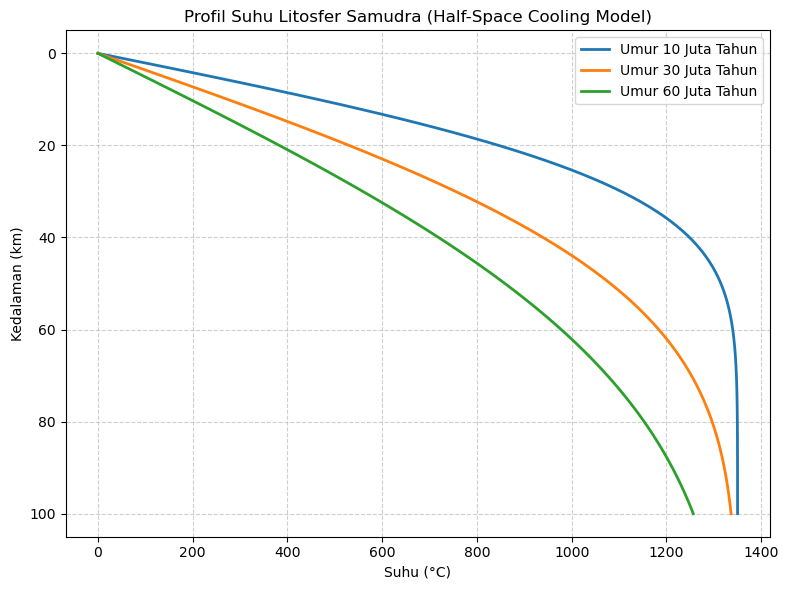

Model pendinginan litosfer berhasil dihitung untuk umur [10, 30, 60] Juta Tahun.


In [15]:
import scipy.special as sp

# Parameter pendinginan litosfer (Half-Space Cooling Model)
T_mantle = 1350.0 # Suhu mantel (C)
kappa = 8e-7      # Difusivitas termal (m^2/s)
seconds_in_myr = 1e6 * 365.25 * 24 * 3600

depths = np.linspace(0, 100000, 100) # Kedalaman 0 - 100 km
ages_myr = [10, 30, 60] # Umur lempeng dalam Juta Tahun

plt.figure(figsize=(8, 6))
for age in ages_myr:
    t_sec = age * seconds_in_myr
    # Solusi analitik: T(z, t) = T_mantle * erf(z / (2 * sqrt(kappa * t)))
    temp = T_mantle * sp.erf(depths / (2 * np.sqrt(kappa * t_sec)))
    plt.plot(temp, depths / 1000, label=f'Umur {age} Juta Tahun', linewidth=2)

plt.gca().invert_yaxis()
plt.xlabel('Suhu (°C)')
plt.ylabel('Kedalaman (km)')
plt.title('Profil Suhu Litosfer Samudra (Half-Space Cooling Model)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

print(
    f"Model pendinginan litosfer berhasil dihitung untuk umur {ages_myr} Juta Tahun.")

## Prompt 5 — Klasifikasi Litologi dengan Machine Learning
Tujuan: melatih model machine learning (Random Forest) untuk klasifikasi litologi dari data log sumur sintetis.

In [17]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score

# Data log sumur sintetis
np.random.seed(42)
n_samples = 1000
gr = np.random.uniform(20, 150, n_samples)       # Gamma Ray
rhob = np.random.uniform(1.9, 2.8, n_samples)    # Bulk Density
nphi = np.random.uniform(0.1, 0.45, n_samples)   # Neutron Porosity

# Simulasi klasifikasi litologi berdasarkan cutoff sederhana + noise
litho = []
for g, r, n in zip(gr, rhob, nphi):
    if g < 50 and r > 2.5:
        litho.append('Batu Gamping')
    elif g > 90 and r < 2.3:
        litho.append('Serpih (Shale)')
    else:
        litho.append('Batu Pasir (Sandstone)')

df_well = pd.DataFrame({
    'GammaRay': gr,
    'Density': rhob,
    'NeutronPorosity': nphi,
    'Litologi': litho
})

X = df_well[['GammaRay', 'Density', 'NeutronPorosity']]
y = df_well['Litologi']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)

rf_model = RandomForestClassifier(n_estimators=50, random_state=42)
rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)

print("Akurasi Model Klasifikasi Litologi:", accuracy_score(y_test, y_pred))
print("\nLaporan Klasifikasi:\n", classification_report(y_test, y_pred))

print("Analisis machine learning log sumur selesai.")

Akurasi Model Klasifikasi Litologi: 0.996

Laporan Klasifikasi:
                         precision    recall  f1-score   support

          Batu Gamping       1.00      0.96      0.98        23
Batu Pasir (Sandstone)       0.99      1.00      1.00       176
        Serpih (Shale)       1.00      1.00      1.00        51

              accuracy                           1.00       250
             macro avg       1.00      0.99      0.99       250
          weighted avg       1.00      1.00      1.00       250

Analisis machine learning log sumur selesai.


## Catatan penggunaan
1. Jalankan sel dari atas ke bawah secara berurutan.
2. Pastikan pustaka seperti `numpy`, `pandas`, `matplotlib`, `scipy`, dan `scikit-learn` sudah terinstal di lingkungan Python Anda.
3. Ganti dataset sintetis dengan data lapangan asli sesuai kebutuhan analisis tugas atau praktikum.